<a href="https://colab.research.google.com/github/priyankamb2725/Natural-Language-Processing/blob/main/LPproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip -q install nltk gensim wordcloud emoji langdetect

In [4]:
import re, html, random, warnings, os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import emoji

from google.colab import files
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer
from nltk.sentiment import SentimentIntensityAnalyzer
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

for package in ["stopwords", "wordnet", "omw-1.4", "vader_lexicon", "punkt", "punkt_tab"]:
    nltk.download(package, quiet=True)

print("Setup complete.")

Setup complete.


In [6]:

import pandas as pd
import urllib.request
import gzip
import json

url = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFiles/Appliances.json.gz"
source = "Appliances.json.gz"

urllib.request.urlretrieve(url, source)

reviews = []
with gzip.open(source, "rt", encoding="utf-8") as f:
    for line in f:
        reviews.append(json.loads(line))
        if len(reviews) == 5000:
            break

df = pd.DataFrame(reviews)

df = df.rename(columns={
    "reviewText": "review_text",
    "overall": "rating",
    "reviewTime": "review_date",
    "asin": "product_id"
})

df = df[["review_text", "rating", "review_date", "product_id"]]
df = df.dropna(subset=["review_text", "rating"])

df.to_csv("customer_reviews_5000.csv", index=False)

print("Dataset shape:", df.shape)
display(df.head())

from google.colab import files
files.download("customer_reviews_5000.csv")

df = pd.read_csv("customer_reviews_5000.csv")
print(df.shape)
display(df.head())

Dataset shape: (5000, 4)


,review_text,rating,review_date,product_id
0,Not one thing in this book seemed an obvious o...,5.0,"11 27, 2013",1118461304
1,I have enjoyed Dr. Alan Gregerman's weekly blo...,5.0,"11 1, 2013",1118461304
2,Alan Gregerman believes that innovation comes ...,5.0,"10 10, 2013",1118461304
3,"Alan Gregerman is a smart, funny, entertaining...",5.0,"10 9, 2013",1118461304
4,"As I began to read this book, I was again remi...",5.0,"09 7, 2013",1118461304


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

(5000, 4)


,review_text,rating,review_date,product_id
0,Not one thing in this book seemed an obvious o...,5.0,"11 27, 2013",1118461304
1,I have enjoyed Dr. Alan Gregerman's weekly blo...,5.0,"11 1, 2013",1118461304
2,Alan Gregerman believes that innovation comes ...,5.0,"10 10, 2013",1118461304
3,"Alan Gregerman is a smart, funny, entertaining...",5.0,"10 9, 2013",1118461304
4,"As I began to read this book, I was again remi...",5.0,"09 7, 2013",1118461304


In [8]:

import pandas as pd
import numpy as np
import re
import urllib.request
import gzip
import json

url = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFiles/Appliances.json.gz"
filename = "Appliances.json.gz"

urllib.request.urlretrieve(url, filename)

reviews = []
with gzip.open(filename, "rt", encoding="utf-8") as f:
    for line in f:
        reviews.append(json.loads(line))
        if len(reviews) >= 5000:
            break

raw = pd.DataFrame(reviews)
print("Dataset shape:", raw.shape)
print("Columns:", raw.columns.tolist())
display(raw.head())


Dataset shape: (5000, 12)
Columns: ['overall', 'vote', 'verified', 'reviewTime', 'reviewerID', 'asin', 'style', 'reviewerName', 'reviewText', 'summary', 'unixReviewTime', 'image']


,overall,vote,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime,image
0,5.0,2,False,"11 27, 2013",A3NHUQ33CFH3VM,1118461304,{'Format:': ' Hardcover'},Greeny,Not one thing in this book seemed an obvious o...,Clear on what leads to innovation,1385510400,NaN
1,5.0,NaN,False,"11 1, 2013",A3SK6VNBQDNBJE,1118461304,{'Format:': ' Kindle Edition'},Leif C. Ulstrup,I have enjoyed Dr. Alan Gregerman's weekly blo...,Becoming more innovative by opening yourself t...,1383264000,NaN
2,5.0,NaN,False,"10 10, 2013",A3SOFHUR27FO3K,1118461304,{'Format:': ' Hardcover'},Harry Gilbert Miller III,Alan Gregerman believes that innovation comes ...,The World from Different Perspectives,1381363200,NaN
3,5.0,NaN,False,"10 9, 2013",A1HOG1PYCAE157,1118461304,{'Format:': ' Hardcover'},Rebecca Ripley,"Alan Gregerman is a smart, funny, entertaining...",Strangers are Your New Best Friends,1381276800,NaN
4,5.0,10,False,"09 7, 2013",A26JGAM6GZMM4V,1118461304,{'Format:': ' Hardcover'},Robert Morris,"As I began to read this book, I was again remi...","How and why it is imperative to engage, learn ...",1378512000,NaN


In [13]:
SEED = 42

if "row_id" not in df.columns:
    df["row_id"] = np.arange(len(df))

if len(df) > 5000:
    df = df.sample(n=5000, random_state=SEED).copy()

df = df.sort_values("row_id").reset_index(drop=True)

print("Selected review count:", len(df))

Selected review count: 5000


In [17]:
import re
import html
import emoji
from nltk.tokenize import RegexpTokenizer
!pip install -q emoji nltk

In [18]:
tokenizer = RegexpTokenizer(r"[a-zA-Z]+(?:'[a-z]+)?")

In [25]:
print(df.columns.tolist())

df["raw_text"] = df["review_text"].fillna("").astype(str)
tokenizer = RegexpTokenizer(r"[a-zA-Z]+(?:'[a-z]+)?")

['review_text', 'rating', 'review_date', 'product_id', 'row_id', 'raw_text']


In [26]:

import re
import html
import emoji
from nltk.tokenize import RegexpTokenizer

tokenizer = RegexpTokenizer(r"[a-zA-Z]+(?:'[a-z]+)?")

def normalise_text(text):
    text = html.unescape(str(text))
    text = emoji.demojize(text, delimiters=(" ", " "))
    text = re.sub(r"https?://\S+|www\.\S+", " URL ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"(.)\1{3,}", r"\1\1", text)
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

df["normalised_text"] = df["raw_text"].map(normalise_text)
df["exact_duplicate"] = df.duplicated(
    subset=["product_id", "normalised_text"], keep="first"
)
df["repeat_across_products"] = (
    df.groupby("normalised_text")["product_id"].transform("nunique") > 3
)
df["url_only"] = df["normalised_text"].str.fullmatch(r"(url\s*)+", na=False)
df["initial_tokens"] = df["normalised_text"].map(tokenizer.tokenize)
df["very_short"] = df["initial_tokens"].map(len) < 3
df["spam_like"] = df["repeat_across_products"] | df["url_only"]

print("Exact duplicates:", int(df["exact_duplicate"].sum()))
print("Very short reviews:", int(df["very_short"].sum()))
print("Spam-like flags:", int(df["spam_like"].sum()))

display(df[["raw_text", "exact_duplicate", "very_short", "spam_like"]].head(10))



Exact duplicates: 146
Very short reviews: 509
Spam-like flags: 197


,raw_text,exact_duplicate,very_short,spam_like
0,Not one thing in this book seemed an obvious o...,False,False,False
1,I have enjoyed Dr. Alan Gregerman's weekly blo...,False,False,False
2,Alan Gregerman believes that innovation comes ...,False,False,False
3,"Alan Gregerman is a smart, funny, entertaining...",False,False,False
4,"As I began to read this book, I was again remi...",False,False,False
5,I teach a class on innovation and I used the N...,False,False,False
6,I so appreciated the insights and perspective ...,False,False,False
7,"As with ""Surrounded by Genius"", Alan Gregerman...",False,False,False
8,Alan Gregermans book provides valuable ideas f...,False,False,False
9,I am a believer in Alan Gregerman. I have enj...,False,False,False


In [28]:
stop_words = set(stopwords.words("english"))
stop_words -= {"no", "nor", "not", "never", "against", "without"}
domain_keep = {
    "battery", "noise", "leak", "motor", "filter", "warranty", "power",
    "heat", "broken", "repair", "service", "delivery", "damaged", "refund",
    "install", "installation", "durable", "quality"
}
stop_words -= domain_keep
lemmatizer = WordNetLemmatizer()

def clean_tokens(text):
    tokens = tokenizer.tokenize(text)
    cleaned = []
    for token in tokens:
        lemma = lemmatizer.lemmatize(token)
        if len(lemma) > 1 and lemma not in stop_words:
            cleaned.append(lemma)
    return cleaned

df["tokens"] = df["normalised_text"].map(clean_tokens)
df["model_text"] = df["tokens"].map(" ".join)

# Primary modelling subset: keep a stable row_id for reliable joins.
model_df = df.loc[
    ~df["exact_duplicate"] & ~df["spam_like"] & ~df["very_short"]
].copy()
model_df = model_df[model_df["tokens"].map(len) >= 3].copy().reset_index(drop=True)

print("Rows available for modelling:", len(model_df))
print("Rows excluded by one or more flags:", len(df) - len(model_df))
display(model_df[["row_id", "raw_text", "tokens"]].head())

Rows available for modelling: 4220
Rows excluded by one or more flags: 780


,row_id,raw_text,tokens
0,0,Not one thing in this book seemed an obvious o...,"[not, one, thing, book, seemed, obvious, origi..."
1,1,I have enjoyed Dr. Alan Gregerman's weekly blo...,"[enjoyed, dr, alan, gregerman's, weekly, blog,..."
2,2,Alan Gregerman believes that innovation comes ...,"[alan, gregerman, belief, innovation, come, vi..."
3,3,"Alan Gregerman is a smart, funny, entertaining...","[alan, gregerman, smart, funny, entertaining, ..."
4,4,"As I began to read this book, I was again remi...","[began, read, book, wa, reminded, deceptively,..."


VADER/rating agreement: 0.731 (73.1%)


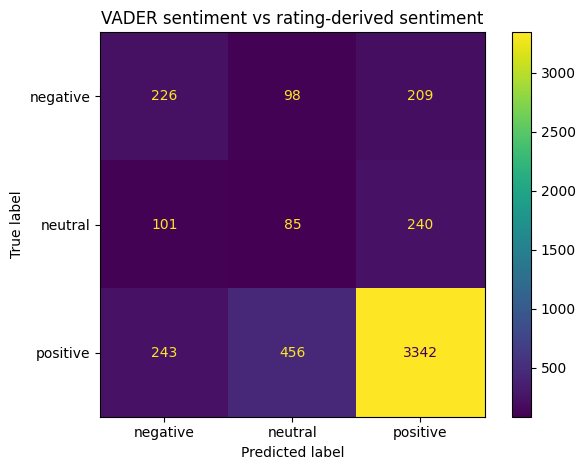

Row-normalised confusion matrix:


vader_sentiment,negative,neutral,positive
rating_sentiment,,,
negative,0.424,0.184,0.392
neutral,0.237,0.200,0.563
positive,0.060,0.113,0.827


Disagreement examples: 1347


,row_id,raw_text,rating,vader_compound,rating_sentiment,vader_sentiment
18,18,"The stated premise of the book, that strangers...",3.0,0.9995,neutral,positive
25,25,"In this engaging, readable book, author Gregr...",3.0,0.9989,neutral,positive
32,32,"In a breezy, conversational book, Gregrerman i...",3.0,0.9676,neutral,positive
39,39,Planning on hooking this to my RV,5.0,0.0000,positive,neutral
44,44,"The cable works well and does what it should, ...",3.0,-0.8890,neutral,negative
50,50,Exactly what I needed and priced right!,5.0,0.0000,positive,neutral
52,52,did what it was intended for,4.0,0.0000,positive,neutral
55,55,Used for my Bosch EV car charger so it is not ...,5.0,-0.2273,positive,negative
57,57,Worked perfect and was cheaper than the same t...,5.0,-0.0516,positive,negative
59,59,The bands are quite useless.\nThe mesh is not ...,3.0,-0.5697,neutral,negative


In [29]:
sia = SentimentIntensityAnalyzer()
vader_scores = df["raw_text"].map(sia.polarity_scores)
df["vader_compound"] = vader_scores.map(lambda x: x["compound"])
df["vader_sentiment"] = np.select(
    [df["vader_compound"] >= 0.05, df["vader_compound"] <= -0.05],
    ["positive", "negative"], default="neutral"
)
df["rating_sentiment"] = np.select(
    [df["rating"] >= 4, df["rating"] <= 2],
    ["positive", "negative"], default="neutral"
)

labels = ["negative", "neutral", "positive"]
agreement = (df["vader_sentiment"] == df["rating_sentiment"]).mean()
print(f"VADER/rating agreement: {agreement:.3f} ({agreement*100:.1f}%)")
cm = confusion_matrix(df["rating_sentiment"], df["vader_sentiment"], labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(values_format="d")
plt.title("VADER sentiment vs rating-derived sentiment")
plt.tight_layout()
plt.show()

print("Row-normalised confusion matrix:")
display(pd.crosstab(df["rating_sentiment"], df["vader_sentiment"], normalize="index").round(3))
disagreements = df.loc[df["vader_sentiment"] != df["rating_sentiment"],
    ["row_id", "raw_text", "rating", "vader_compound", "rating_sentiment", "vader_sentiment"]]
print("Disagreement examples:", len(disagreements))
display(disagreements.head(20))
disagreements.to_csv("sentiment_disagreements.csv", index=False)

In [33]:
texts = model_df["tokens"].tolist()
dictionary = corpora.Dictionary(texts)
dictionary.filter_extremes(no_below=5, no_above=0.70, keep_n=10000)
corpus_pairs = [(tokens, dictionary.doc2bow(tokens)) for tokens in texts]
corpus_pairs = [(tokens, bow) for tokens, bow in corpus_pairs if len(bow) > 0]
texts = [x[0] for x in corpus_pairs]
corpus = [x[1] for x in corpus_pairs]




In [37]:


lda_models = {}
coherence_rows = []

for k in range(3, 9):  # Test 6 topic counts instead of 10
    lda_model = LdaModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=k,
        random_state=SEED,
        passes=3,
        iterations=30,
        alpha="auto",
        per_word_topics=False
    )

    coherence = CoherenceModel(
        model=lda_model,
        texts=texts,
        dictionary=dictionary,
        coherence="c_v",
        processes=1
    ).get_coherence()

    lda_models[k] = lda_model
    coherence_rows.append({
        "num_topics": k,
        "c_v_coherence": coherence
    })

coherence_df = pd.DataFrame(coherence_rows)
display(coherence_df)

coherence_df.to_csv("lda_coherence_scores.csv", index=False)

best_k = coherence_df.loc[
    coherence_df["c_v_coherence"].idxmax(), "num_topics"
]
print("Best number of topics:", int(best_k))


,num_topics,c_v_coherence
0,3,0.418595
1,4,0.433652
2,5,0.421996
3,6,0.398374
4,7,0.368974
5,8,0.377640


Best number of topics: 4


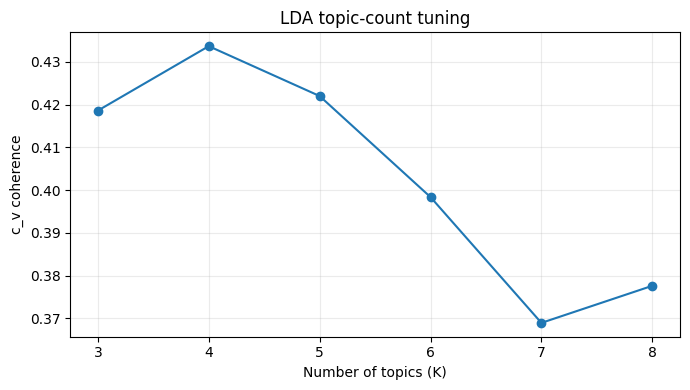

In [38]:
plt.figure(figsize=(7, 4))
plt.plot(coherence_df["num_topics"], coherence_df["c_v_coherence"], marker="o")
plt.xlabel("Number of topics (K)")
plt.ylabel("c_v coherence")
plt.title("LDA topic-count tuning")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig("lda_coherence_tuning.png", dpi=160)
plt.show()

In [39]:
best_k = int(coherence_df.loc[coherence_df["c_v_coherence"].idxmax(), "num_topics"])
lda = lda_models[best_k]
best_coherence = float(coherence_df["c_v_coherence"].max())
print(f"Best K by c_v coherence: {best_k}; score: {best_coherence:.4f}")
print("Meets >0.45 target:", best_coherence > 0.45)

Best K by c_v coherence: 4; score: 0.4337
Meets >0.45 target: False


In [40]:
def get_topic_distribution(bow):
    return sorted(lda.get_document_topics(bow, minimum_probability=0),
                  key=lambda pair: pair[1], reverse=True)

dominant_topics, topic_probs = [], []
for bow in corpus:
    dist = get_topic_distribution(bow)
    dominant_topics.append(int(dist[0][0]))
    topic_probs.append(float(dist[0][1]))

topic_docs = model_df.iloc[:len(dominant_topics)].copy()
# Align by the exact sequence used to construct texts/corpus.
topic_docs["dominant_topic"] = dominant_topics
topic_docs["topic_probability"] = topic_probs

for topic_id in range(best_k):
    print("\\n" + "="*70)
    print(f"TOPIC {topic_id}:")
    print(", ".join(word for word, weight in lda.show_topic(topic_id, topn=12)))
    examples = topic_docs[topic_docs["dominant_topic"] == topic_id].nlargest(5, "topic_probability")
    print("\nRepresentative reviews:")
    for text in examples["raw_text"].tolist():
        print("-", text[:500])

topic_docs[["row_id", "dominant_topic", "topic_probability"]].to_csv("review_topic_assignments.csv", index=False)

\n======================================================================
TOPIC 0:
cover, burner, wa, stove, not, one, look, set, black, color, well, kitchen

Representative reviews:
- I'm extremely disappointed, and would never, ever again buy this kind of product online.  Next time I'll make that trip to the mall. When shopping, I found pictures of two sets that looked very similar, one set priced around $7, and one at $15.  I ordered the more expensive set, thinking it would surely be better quality.  Well, I'd hate to see the $7 set.  The one I received is paper-thin, very light, tinny, feels almost like plastic.  I made the mistake of trying to sit a hot pan down on one, 
- Prior to this purchase, I've bought covers from this company for both our old 24" electric stove and our newer 30" gas stove.  This set was for the electric stove which has 3 small burners and 1 large one.  Usually, I cover one back burner with a tea kettle rather than buy two sets of covers since most manufactu

In [45]:
print(topic_docs.columns.tolist())

['review_text', 'rating', 'review_date', 'product_id', 'row_id', 'raw_text', 'normalised_text', 'exact_duplicate', 'repeat_across_products', 'url_only', 'initial_tokens', 'very_short', 'spam_like', 'tokens', 'model_text', 'dominant_topic', 'topic_probability', 'theme', 'negative_by_rating']


In [46]:

!pip install -q vaderSentiment

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

topic_docs["vader_compound"] = topic_docs["raw_text"].fillna("").astype(str).apply(
    lambda text: analyzer.polarity_scores(text)["compound"]
)

print(topic_docs[["raw_text", "vader_compound"]].head())


                                            raw_text  vader_compound
0  Not one thing in this book seemed an obvious o...          0.9836
1  I have enjoyed Dr. Alan Gregerman's weekly blo...          0.9925
2  Alan Gregerman believes that innovation comes ...          0.9606
3  Alan Gregerman is a smart, funny, entertaining...          0.9859
4  As I began to read this book, I was again remi...          0.9989


In [49]:
!pip install -q vaderSentiment

In [51]:

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import pandas as pd
import numpy as np

topic_docs["review_date"] = pd.to_datetime(
    topic_docs["review_date"],
    errors="coerce",
    format="mixed",
    utc=True
).dt.tz_convert(None)

dated = topic_docs.dropna(subset=["review_date"]).copy()

if not dated.empty:
    dated["month"] = dated["review_date"].dt.to_period("M")

# Ensure required columns exist
if "raw_text" not in topic_docs.columns:
    raise ValueError("Missing raw_text. Run the data preparation cell first.")

if "vader_compound" not in topic_docs.columns:
    analyzer = SentimentIntensityAnalyzer()
    topic_docs["vader_compound"] = topic_docs["raw_text"].fillna("").astype(str).apply(
        lambda x: analyzer.polarity_scores(x)["compound"]
    )

required = ["dominant_topic", "rating", "row_id", "review_date"]
missing = [c for c in required if c not in topic_docs.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}. Check earlier notebook cells.")

# Temporary topic labels
TOPIC_LABELS = {
    i: f"Topic {i} — review required"
    for i in range(int(best_k))
}

topic_docs["theme"] = topic_docs["dominant_topic"].map(TOPIC_LABELS)
topic_docs["negative_by_rating"] = topic_docs["rating"] <= 2
topic_docs["negative_by_vader"] = topic_docs["vader_compound"] <= -0.05

summary = topic_docs.groupby(["dominant_topic", "theme"]).agg(
    review_count=("row_id", "count"),
    mean_rating=("rating", "mean"),
    negative_rating_share=("negative_by_rating", "mean"),
    negative_vader_share=("negative_by_vader", "mean"),
    mean_vader_compound=("vader_compound", "mean")
).reset_index()

summary["review_share"] = summary["review_count"] / len(topic_docs)

# Compare the latest 3 calendar months with the previous 3
dated = topic_docs.dropna(subset=["review_date"]).copy()

if not dated.empty:
    dated["month"] = dated["review_date"].dt.to_period("M")
    last_month = dated["month"].max()

    recent = dated[
        dated["month"].between(last_month - 2, last_month)
    ].groupby("dominant_topic").size()

    prior = dated[
        dated["month"].between(last_month - 5, last_month - 3)
    ].groupby("dominant_topic").size()

    growth_map = {}
    for t in range(int(best_k)):
        r, p = int(recent.get(t, 0)), int(prior.get(t, 0))
        growth_map[t] = (r - p) / p if p > 0 else (1.0 if r > 0 else 0.0)

    summary["recent_growth"] = summary["dominant_topic"].map(growth_map).fillna(0)
else:
    summary["recent_growth"] = 0.0

# Normalise scores
def minmax(series):
    lo, hi = series.min(), series.max()
    if pd.isna(lo) or pd.isna(hi) or hi == lo:
        return pd.Series(0.0, index=series.index)
    return (series - lo) / (hi - lo)

summary["frequency_norm"] = minmax(summary["review_share"])
summary["negativity_norm"] = minmax(summary["negative_rating_share"])
summary["growth_norm"] = minmax(summary["recent_growth"])

summary["priority_score"] = (
    0.40 * summary["frequency_norm"]
    + 0.35 * summary["negativity_norm"]
    + 0.25 * summary["growth_norm"]
)

summary = summary.sort_values("priority_score", ascending=False)

display(summary.round(3))
summary.to_csv("theme_summary.csv", index=False)

print("Saved theme_summary.csv")


,dominant_topic,theme,review_count,mean_rating,negative_rating_share,negative_vader_share,mean_vader_compound,review_share,recent_growth,frequency_norm,negativity_norm,growth_norm,priority_score
0,0,Topic 0 — review required,1054,4.209,0.121,0.118,0.511,0.250,-0.029,0.449,0.205,1.000,0.501
3,3,Topic 3 — review required,1590,4.380,0.086,0.079,0.488,0.377,-0.721,1.000,0.015,0.012,0.408
2,2,Topic 2 — review required,617,3.553,0.269,0.222,0.332,0.146,-0.625,0.000,1.000,0.150,0.387
1,1,Topic 1 — review required,959,4.358,0.083,0.122,0.516,0.227,-0.730,0.351,0.000,0.000,0.141


Saved theme_summary.csv


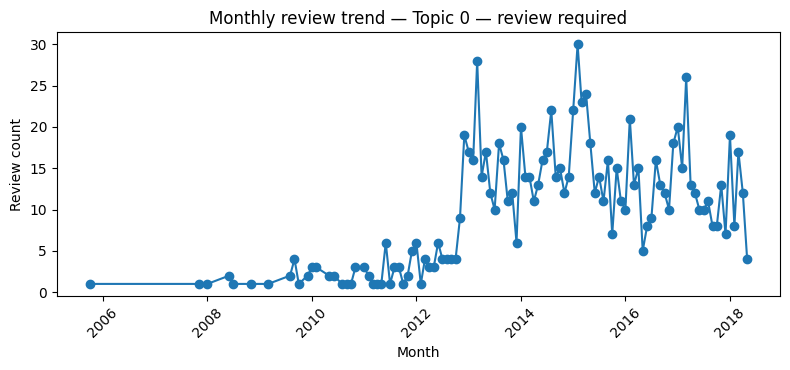

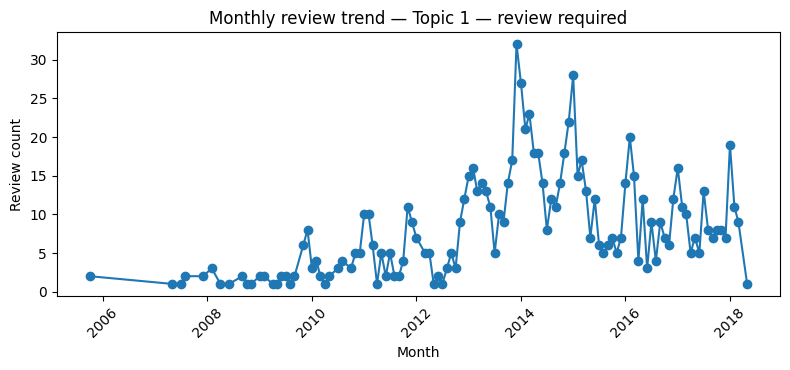

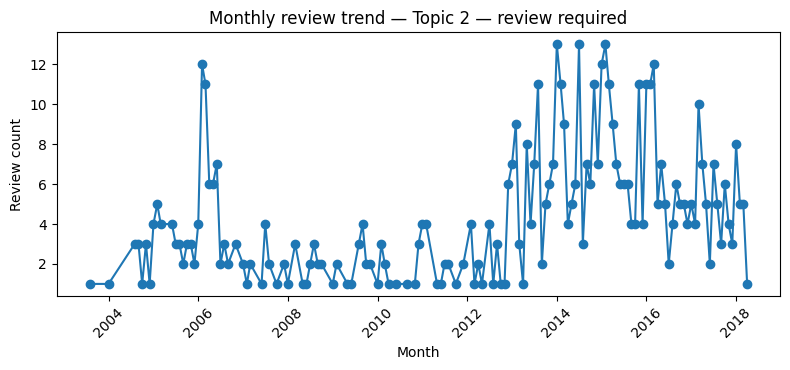

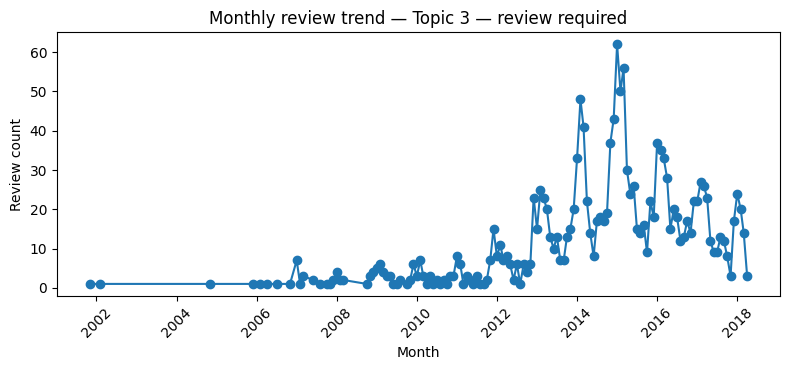

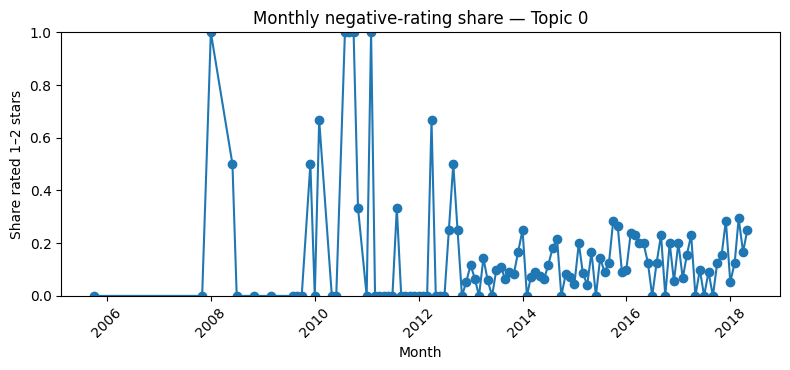

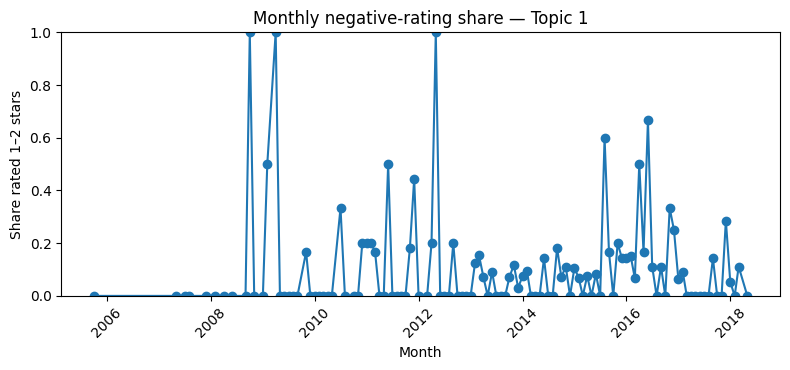

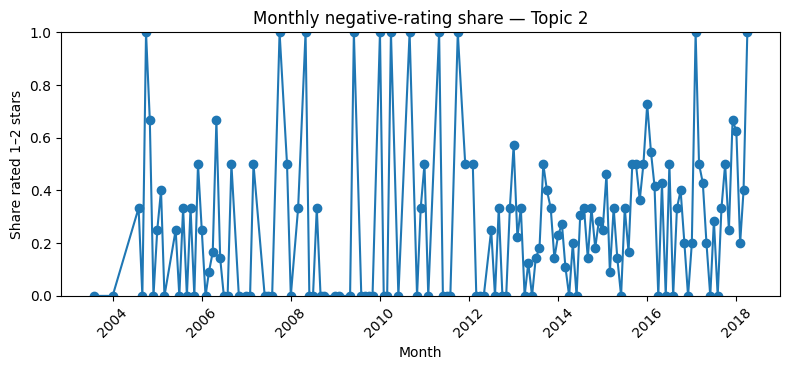

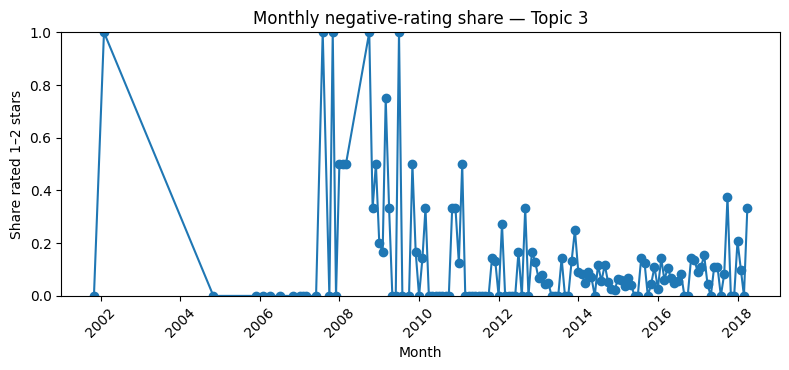

In [52]:
trend_df = topic_docs.dropna(subset=["review_date"]).copy()
trend_df["month"] = trend_df["review_date"].dt.to_period("M").dt.to_timestamp()
monthly_counts = trend_df.groupby(["month", "dominant_topic"]).size().rename("review_count").reset_index()

for topic_id in sorted(topic_docs["dominant_topic"].unique()):
    part = monthly_counts[monthly_counts["dominant_topic"] == topic_id].sort_values("month")
    if part.empty:
        continue
    label = TOPIC_LABELS.get(int(topic_id), f"Topic {topic_id}")
    plt.figure(figsize=(8, 3.8))
    plt.plot(part["month"], part["review_count"], marker="o")
    plt.title(f"Monthly review trend — {label}")
    plt.xlabel("Month")
    plt.ylabel("Review count")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(f"topic_{int(topic_id)}_trend.png", dpi=160)
    plt.show()

# Also plot monthly negative-rating share by topic.
monthly_neg = trend_df.groupby(["month", "dominant_topic"])["negative_by_rating"].mean().reset_index()
for topic_id in sorted(trend_df["dominant_topic"].unique()):
    part = monthly_neg[monthly_neg["dominant_topic"] == topic_id].sort_values("month")
    if part.empty:
        continue
    plt.figure(figsize=(8, 3.8))
    plt.plot(part["month"], part["negative_by_rating"], marker="o")
    plt.title(f"Monthly negative-rating share — Topic {int(topic_id)}")
    plt.xlabel("Month")
    plt.ylabel("Share rated 1–2 stars")
    plt.ylim(0, 1)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig(f"topic_{int(topic_id)}_negative_trend.png", dpi=160)
    plt.show()

In [53]:
annotation_sample = df.sample(n=min(300, len(df)), random_state=SEED)[
    ["row_id", "product_id", "review_date", "rating", "raw_text"]
].copy()
annotation_sample["theme_label"] = ""
annotation_sample.to_csv("reviews_to_label.csv", index=False)
files.download("reviews_to_label.csv")
print("Download the CSV, manually fill theme_label, then upload it back when finished.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download the CSV, manually fill theme_label, then upload it back when finished.


In [57]:

!pip install -q scikit-learn

import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

uploaded_labels = files.upload()
label_files = [name for name in uploaded_labels if name.lower().endswith(".csv")]

if label_files:
    labelled = pd.read_csv(label_files[0])

    required_cols = {"raw_text", "theme_label"}
    if not required_cols.issubset(labelled.columns):
        raise ValueError("CSV must contain raw_text and theme_label columns.")

    labelled["raw_text"] = labelled["raw_text"].fillna("").astype(str).str.strip()
    labelled["theme_label"] = labelled["theme_label"].fillna("").astype(str).str.strip()

    labelled = labelled[
        labelled["raw_text"].ne("") & labelled["theme_label"].ne("")
    ].copy()

    # Remove duplicate text to reduce data leakage
    labelled = labelled.drop_duplicates(subset=["raw_text"])

    print("Usable labelled reviews:", len(labelled))
    display(labelled["theme_label"].value_counts().to_frame("count"))

    if len(labelled) < 10 or labelled["theme_label"].nunique() < 2:
        raise ValueError("Add more labelled reviews with at least 2 different classes.")

    counts = labelled["theme_label"].value_counts()
    can_stratify = counts.min() >= 2

    # Use 100 test reviews when 300 or more are available
    test_n = 100 if len(labelled) >= 300 else max(1, round(len(labelled) / 3))

    train, test = train_test_split(
        labelled,
        test_size=test_n,
        random_state=SEED,
        stratify=labelled["theme_label"] if can_stratify else None
    )

    classifier = Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2), min_df=1,
            max_features=20000, sublinear_tf=True
        )),
        ("model", LogisticRegression(
            max_iter=1000, class_weight="balanced",
            random_state=SEED
        ))
    ])

    classifier.fit(train["raw_text"], train["theme_label"])
    predictions = classifier.predict(test["raw_text"])

    print("Training reviews:", len(train))
    print("Testing reviews:", len(test))
    print(f"Test accuracy: {accuracy_score(test['theme_label'], predictions):.3f}")
    print(classification_report(
        test["theme_label"], predictions, zero_division=0
    ))

    class_names = sorted(labelled["theme_label"].unique())
    cm = confusion_matrix(test["theme_label"], predictions, labels=class_names)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    ).plot(xticks_rotation=45)

    plt.tight_layout()
    plt.show()

else:
    print("No labelled CSV uploaded. Complete manual annotation first.")


Saving Customer_Review_Text_Analysis_Report.docx to Customer_Review_Text_Analysis_Report.docx
No labelled CSV uploaded. Complete manual annotation first.


In [61]:

from pathlib import Path
from google.colab import files

# Export main tables
df.to_csv("cleaning_audit_and_sentiment.csv", index=False)
topic_docs.to_csv("reviews_with_topics.csv", index=False)
summary.to_csv("theme_summary.csv", index=False)
coherence_df.to_csv("lda_coherence_scores.csv", index=False)

print("Generated CSV and PNG files:")
for p in sorted(Path(".").glob("*.csv")):
    print("-", p.name)

for p in sorted(Path(".").glob("*.png")):
    print("-", p.name)

# Download important outputs if they exist
download_files = [
    "theme_summary.csv",
    "lda_coherence_scores.csv",
    "cleaning_audit_and_sentiment.csv",
    "reviews_with_topics.csv",
    "review_wordcloud.png"
]

for filename in download_files:
    if Path(filename).exists():
        print("Downloading:", filename)
        files.download(filename)
    else:
        print("Not found, skipped:", filename)


Generated CSV and PNG files:
- cleaning_audit_and_sentiment.csv
- customer_reviews_5000 (1).csv
- customer_reviews_5000.csv
- lda_coherence_scores.csv
- review_topic_assignments.csv
- reviews_to_label (1).csv
- reviews_to_label.csv
- reviews_with_topics.csv
- sentiment_disagreements.csv
- theme_summary.csv
- lda_coherence_tuning.png
- topic_0_negative_trend.png
- topic_0_trend.png
- topic_1_negative_trend.png
- topic_1_trend.png
- topic_2_negative_trend.png
- topic_2_trend.png
- topic_3_negative_trend.png
- topic_3_trend.png
Downloading: theme_summary.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: lda_coherence_scores.csv


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

Downloading: reviews_with_topics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Not found, skipped: review_wordcloud.png
